# Fairness-Aware XAI Audit - complete walkthrough (Google Colab)

This single notebook runs the **whole project from start to finish** and explains every block:
data -> preprocessing -> models -> fairness (RQ1) -> SHAP & LIME explanations -> comparison across groups (RQ2)
-> statistical tests (RQ3) -> trade-off (RQ4) -> bias mitigation -> explanation stability.

Every block has an explanation cell above it with four parts:

* **What** - what the code does
* **Why** - the reasoning behind the design choice
* **Look for** - what to check in the output
* **Viva tip** - a short sentence you can use to explain it

The code itself lives in the project's `src/` package (cloned from GitHub). This notebook *calls* that code and, for
the crucial functions, *prints their real source* with `show_source(...)`, so what you see is exactly what runs.

### How to run
1. In Colab: **Runtime -> Change runtime type -> CPU** is enough (no GPU needed).
2. Run the cells **from top to bottom** (Runtime -> Run all).
3. If Colab asks to **Restart session** after installing libraries, click it and run the cells again from the top.
4. `QUICK = True` (section 0.3) gives a dry run in about 5 minutes; `QUICK = False` is the complete run
   (roughly 20-40 minutes on Colab's CPU).

### Contents
0. Setup · 1. Configuration · 2. Data · 3. Preprocessing · 4. Models & performance · 5. Fairness (RQ1) ·
6. Explanations · 7. Comparison across groups (RQ2) · 8. Statistical tests (RQ3) · 9. Trade-off (RQ4) ·
10. Bias mitigation · 11. Stability · 12. Tests · 13. Summary of findings · 14. Save results

## 0. Setup

### 0.1 Get the project and install libraries
**What:** in Colab, clones the project from GitHub into `/content/fairness-xai` (or uses a copy in Google Drive if
`USE_DRIVE = True`), installs the exact library versions from `requirements.txt` once, and makes `src/` importable.
Locally it simply finds the project folder.

**Why:** pinned versions (e.g. `shap==0.48.0`, `scikit-learn==1.5.2`, `fairlearn==0.12.0`) make results reproducible;
newer versions can change APIs or numbers.

**Look for:** `Project root: /content/fairness-xai`.

**Viva tip:** "The notebook and the dashboard use the same `src` package, so there is one implementation of every step."

In [1]:
# ---------------------------------------------------------------------------
# 0.1 Get the project and install the pinned libraries
# ---------------------------------------------------------------------------
import importlib.metadata
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Titan-Bear/fairness-xai.git"   # public repository
USE_DRIVE = False                                             # True: use a copy in Google Drive instead
DRIVE_PROJECT = "/content/drive/MyDrive/fairness-xai"

if IN_COLAB:
    if USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_ROOT = Path(DRIVE_PROJECT)
    else:
        PROJECT_ROOT = Path("/content/fairness-xai")
        if not PROJECT_ROOT.exists():
            subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_ROOT)], check=True)
    try:
        installed = importlib.metadata.version("shap") == "0.48.0"
    except importlib.metadata.PackageNotFoundError:
        installed = False
    if not installed:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                        str(PROJECT_ROOT / "requirements.txt")], check=True)
        print("Libraries installed. If Colab shows 'Restart session', click it, then run this cell again.")
else:
    # Running locally (Jupyter / VS Code) from the notebooks/ folder.
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: C:\Users\tarun\Desktop\Mini Project\fairness-xai


### 0.2 Imports and a helper to show source code
**What:** imports the project modules and defines `show_source(function)`, which prints a function's real code.

**Why:** the explanations below refer to specific functions; printing their source keeps the notebook and the code
in sync.

**Look for:** the printed library versions match `requirements.txt`.

In [2]:
%matplotlib inline
import inspect
import warnings

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src import config
from src import compare, data, evaluate, explain, fairness, mitigation, models, preprocess, stability, stats

warnings.filterwarnings("ignore", category=FutureWarning)
config.setup_logging()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)


def show_source(obj) -> None:
    """Print the real source code of a project function or class."""
    display(Markdown(f"```python\n{inspect.getsource(obj)}\n```"))


for lib in ["pandas", "numpy", "scikit-learn", "xgboost", "shap", "lime", "fairlearn"]:
    print(f"{lib:14s} {importlib.metadata.version(lib)}")

pandas         2.2.3
numpy          2.1.3
scikit-learn   1.5.2
xgboost        2.1.4
shap           0.48.0
lime           0.2.0.1
fairlearn      0.12.0


C:\Users\tarun\Desktop\Mini Project\fairness-xai\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 0.3 Choose quick or complete run
**What:** `QUICK = True` uses tiny samples (10-20 people per group, 100 bootstrap resamples) and writes to
`results/quick/`. `QUICK = False` uses the full settings from `src/config.py`.

**Why:** the quick run checks that everything works in a few minutes; the complete run produces the real results.
Writing quick results to a separate folder means a test run never overwrites real results.

**Viva tip:** "All tunable values - seed, sample sizes, model parameters - are in one file, `src/config.py`."

In [3]:
QUICK = False   # True = ~5 minute dry run, False = complete run

if QUICK:
    config.set_results_dir(config.PROJECT_ROOT / "results" / "quick")
EXPLAIN_SETTINGS = explain.QUICK_SETTINGS if QUICK else explain.ExplainSettings()
STABILITY_SETTINGS = stability.QUICK_STABILITY if QUICK else stability.StabilitySettings()
N_BOOT = config.QUICK_N_BOOTSTRAP if QUICK else config.N_BOOTSTRAP
config.ensure_dirs()
print("Results folder:", config.RESULTS_DIR)
print("Explanation sample:", EXPLAIN_SETTINGS)
print("Stability sample:", STABILITY_SETTINGS, "| bootstrap resamples:", N_BOOT)

Results folder: C:\Users\tarun\Desktop\Mini Project\fairness-xai\results
Explanation sample: ExplainSettings(shap_n_per_group=200, lime_n_per_group=100, lime_num_samples=1000, seed=42)
Stability sample: StabilitySettings(n_instances=100, seeds=(42, 43, 44), lime_samples=1000) | bootstrap resamples: 1000


## 1. Configuration (`src/config.py`)
**What:** prints the key settings used everywhere in the project.

**Why:** one seed (42) for splits, models, sampling, LIME and bootstrap makes every number reproducible. The two
**settings** are the core experiment: models trained *with* the sensitive features (sex, race) and *without* them
("fairness through unawareness"), to test whether other features act as **proxies**.

**Look for:** seed 42, test size 0.30, two settings, three models, Random Forest with `min_samples_leaf=5`.

**Viva tip:** "`min_samples_leaf=5` was added because the default forest memorised COMPAS: 0.84 training accuracy but
0.62 test accuracy; with 5 it reaches 0.667."

In [4]:
print("Seed:", config.SEED, "| test size:", config.TEST_SIZE)
print("Settings:", config.SETTINGS)
print("Models:", config.MODEL_NAMES)
print("Random Forest:", config.RF_PARAMS)
print("XGBoost:", config.XGB_PARAMS)
print("SHAP / LIME instances per group:", config.SHAP_N_PER_GROUP, "/", config.LIME_N_PER_GROUP,
      "| LIME samples:", config.LIME_NUM_SAMPLES)
print("Mitigation:", config.RUN_MITIGATION, "| Stability:", config.RUN_STABILITY,
      "| noise levels:", config.STABILITY_NOISE_LEVELS)

Seed: 42 | test size: 0.3
Settings: {'with_sensitive': True, 'without_sensitive': False}
Models: ('logistic_regression', 'random_forest', 'xgboost')
Random Forest: {'n_estimators': 300, 'min_samples_leaf': 5, 'n_jobs': -1, 'random_state': 42}
XGBoost: {'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.1, 'eval_metric': 'logloss', 'random_state': 42, 'n_jobs': -1}
SHAP / LIME instances per group: 200 / 100 | LIME samples: 1000
Mitigation: True | Stability: True | noise levels: (0.01, 0.05, 0.1)


## 2. Data (`src/data.py`)

### 2.1 Load both datasets
**What:** `load_adult()` downloads Adult Income via fairlearn (OpenML, cached in `data/raw/`); `load_compas()`
downloads ProPublica's COMPAS file. Each returns `X` (features), `y` (target), `sensitive` (group labels) and
`metadata` (column lists, privileged groups).

**Why the cleaning choices:**
* Adult: target = income > 50K; `fnlwgt` (a census sampling weight) and `education` (duplicated by `education-num`)
  are dropped; rows with `?` removed; race binarised to White / Non-White so every comparison has two groups.
* COMPAS: ProPublica's standard filters; only African-American and Caucasian defendants.

**Look for:** Adult 45,222 rows, COMPAS 5,278 rows.

In [5]:
adult = data.load_adult()
compas = data.load_compas()
for d in (adult, compas):
    m = d.metadata
    print(f"{config.DATASET_DISPLAY_NAMES[m.name]}: {len(d.X):,} rows, {d.X.shape[1]} features, "
          f"positive rate {d.y.mean():.3f}")
    print("   sensitive:", m.sensitive_attributes, "| privileged:", m.privileged)
display(adult.X.head(3))
display(compas.X.head(3))

16:09:38 | INFO    | src.data | Loaded Adult from OpenML via fairlearn (48842 rows).


16:09:38 | INFO    | src.data | Adult ready: 45222 rows, 12 features, positive rate 0.248.


16:09:38 | INFO    | src.data | COMPAS ready: 5278 rows, 8 features, positive rate 0.470.


Adult Income: 45,222 rows, 12 features, positive rate 0.248
   sensitive: ['sex', 'race'] | privileged: {'sex': 'Male', 'race': 'White'}
COMPAS: 5,278 rows, 8 features, positive rate 0.470
   sensitive: ['race', 'sex'] | privileged: {'race': 'Caucasian', 'sex': 'Female'}


,age,education-num,capital-gain,capital-loss,hours-per-week,workclass,marital-status,occupation,relationship,race,sex,native-country
0,25,7,0,0,40,Private,Never-married,Machine-op-inspct,Own-child,Non-White,Male,United-States
1,38,9,0,0,50,Private,Married-civ-spouse,Farming-fishing,Husband,White,Male,United-States
2,28,12,0,0,40,Local-gov,Married-civ-spouse,Protective-serv,Husband,White,Male,United-States


,age,priors_count,juv_fel_count,juv_misd_count,juv_other_count,sex,race,c_charge_degree
0,34,0,0,0,0,Male,African-American,F
1,24,4,0,0,1,Male,African-American,F
2,41,14,0,0,0,Male,Caucasian,F


### 2.2 Target leakage check and the filters
**What:** confirms COMPAS's own risk scores are not features, and shows the filter code.

**Why:** `decile_score`, `score_text` and `v_decile_score` are the COMPAS tool's output. Using them would be **target
leakage** - predicting re-offending from a score built to predict re-offending - and would copy the bias we audit.

**Viva tip:** "We audit the data, not the COMPAS tool's score, so its scores are excluded."

In [6]:
print("Leakage columns in COMPAS features:",
      [c for c in data.COMPAS_LEAKAGE_COLUMNS if c in compas.X.columns] or "none")
show_source(data.apply_propublica_filters)

Leakage columns in COMPAS features: none


```python
def apply_propublica_filters(df: pd.DataFrame) -> pd.DataFrame:
    """Apply ProPublica's standard data-quality filters.

    * days_b_screening_arrest in [-30, 30]: if the COMPAS screening was far
      from the arrest date, we may be looking at the wrong offence.
    * is_recid != -1: -1 means no COMPAS case was found.
    * c_charge_degree != "O": ordinary traffic offences do not lead to jail.
    * score_text != "N/A": the score is missing.
    Rows with a missing days_b_screening_arrest are also dropped, because
    `between` returns False for NaN (the same as ProPublica's R analysis).
    """
    mask = (
        df["days_b_screening_arrest"].between(-30, 30)
        & (df["is_recid"] != -1)
        & (df["c_charge_degree"] != "O")
        & (df["score_text"] != "N/A")
    )
    return df.loc[mask].copy()

```

### 2.3 Group sizes and base rates
**What:** for each sensitive attribute, the number of people per group and the **base rate** (share with y = 1).

**Why:** if base rates differ, even a perfectly accurate model predicts the positive class more often for one group,
so it has a demographic-parity gap. That is why we also measure **equal opportunity**.

**Look for:** Adult: 31.2% of men vs 11.4% of women earn >50K. COMPAS: 52.3% of African-American vs 39.1% of
Caucasian defendants re-offended.

In [7]:
rows = []
for d in (adult, compas):
    for attribute in d.metadata.sensitive_attributes:
        for group, idx in d.sensitive.groupby(attribute).groups.items():
            rows.append({"dataset": d.metadata.name, "attribute": attribute, "group": group,
                         "privileged": group == d.metadata.privileged[attribute],
                         "count": len(idx), "base_rate": d.y.loc[idx].mean()})
display(pd.DataFrame(rows).round(3))

,dataset,attribute,group,privileged,count,base_rate
0,adult,sex,Female,False,14695,0.114
1,adult,sex,Male,True,30527,0.312
2,adult,race,Non-White,False,6319,0.158
3,adult,race,White,True,38903,0.262
4,compas,race,African-American,False,3175,0.523
5,compas,race,Caucasian,True,2103,0.391
6,compas,sex,Female,True,1031,0.362
7,compas,sex,Male,False,4247,0.497


## 3. Preprocessing (`src/preprocess.py`)

### 3.1 Stratified 70/30 split
**What:** `prepare_dataset` loads, splits and saves each dataset. The split is **stratified** on the target, so train
and test keep the same share of positives.

**Why:** the code splits the *row indices* once and uses them for X, y and the sensitive labels, so every test row
keeps its group label. The split does not depend on the columns, so both settings use exactly the same rows - a fair
comparison.

**Look for:** equal positive rates in train and test; group counts per test set.

In [8]:
prepared = {name: preprocess.prepare_dataset(name) for name in config.DATASETS}
for name, (loaded, split) in prepared.items():
    print(f"{name}: train {len(split.X_train):,} | test {len(split.X_test):,} | positive rate "
          f"{split.y_train.mean():.3f} / {split.y_test.mean():.3f}")
    for attribute in loaded.metadata.sensitive_attributes:
        print(f"   test rows by {attribute}: {split.s_test[attribute].value_counts().to_dict()}")
show_source(preprocess.split_data)

16:09:39 | INFO    | src.data | Loaded Adult from OpenML via fairlearn (48842 rows).


16:09:39 | INFO    | src.data | Adult ready: 45222 rows, 12 features, positive rate 0.248.


16:09:39 | INFO    | src.preprocess | Saved adult_train.csv (31655 rows).


16:09:39 | INFO    | src.preprocess | Saved adult_test.csv (13567 rows).


16:09:39 | INFO    | src.data | COMPAS ready: 5278 rows, 8 features, positive rate 0.470.


16:09:39 | INFO    | src.preprocess | Saved compas_train.csv (3694 rows).


16:09:39 | INFO    | src.preprocess | Saved compas_test.csv (1584 rows).


adult: train 31,655 | test 13,567 | positive rate 0.248 / 0.248
   test rows by sex: {'Male': 9140, 'Female': 4427}
   test rows by race: {'White': 11669, 'Non-White': 1898}
compas: train 3,694 | test 1,584 | positive rate 0.470 / 0.470
   test rows by race: {'African-American': 947, 'Caucasian': 637}
   test rows by sex: {'Male': 1270, 'Female': 314}


```python
def split_data(
    X: pd.DataFrame,
    y: pd.Series,
    sensitive: pd.DataFrame,
    test_size: float = config.TEST_SIZE,
    seed: int = config.SEED,
) -> SplitData:
    """Stratified train/test split that keeps `sensitive` aligned with X.

    We split the row *indices* once and use them for X, y and sensitive, so
    the three can never get out of step. Because the split does not depend on
    which columns X has, both settings (with/without sensitive features) use
    exactly the same train and test rows, which makes them comparable.
    """
    train_idx, test_idx = train_test_split(
        X.index.to_numpy(),
        test_size=test_size,
        stratify=y,
        random_state=seed,
    )
    return SplitData(
        X_train=X.loc[train_idx],
        X_test=X.loc[test_idx],
        y_train=y.loc[train_idx],
        y_test=y.loc[test_idx],
        s_train=sensitive.loc[train_idx],
        s_test=sensitive.loc[test_idx],
    )

```

### 3.2 The preprocessor
**What:** a `ColumnTransformer` that standardises numeric columns and one-hot encodes categorical columns.

**Why:**
* Scaling helps Logistic Regression and LIME's perturbations; trees do not need it, but one shared preprocessor keeps
  the models comparable.
* `handle_unknown="ignore"`: a category seen only in the test set becomes all zeros instead of crashing.
* It is placed **inside each model's Pipeline**, so it is fitted on training data only - no test-set leakage.
* In the "without sensitive" setting, `select_feature_columns` drops sex and race, and the transformer drops every
  column it was not given.

In [9]:
show_source(preprocess.build_preprocessor)
loaded, split = prepared["adult"]
for setting, include in config.SETTINGS.items():
    numeric, categorical = preprocess.select_feature_columns(loaded.metadata, include)
    pre = preprocess.build_preprocessor(numeric, categorical)
    X_train_t, X_test_t = preprocess.fit_transform_frame(pre, split.X_train, split.X_test)
    print(f"{setting}: {X_train_t.shape[1]} transformed columns, missing values: {int(X_train_t.isna().sum().sum())}")

```python
def build_preprocessor(numeric: list[str], categorical: list[str]) -> ColumnTransformer:
    """Build the (unfitted) ColumnTransformer.

    * StandardScaler on numeric columns: Logistic Regression and LIME's
      perturbations both work better when features share a scale. Trees do
      not need it, but one shared preprocessor keeps the models comparable.
    * OneHotEncoder(handle_unknown="ignore"): a category seen only in the test
      set becomes all zeros instead of crashing. Dense output because SHAP and
      LIME expect dense arrays.
    * verbose_feature_names_out=False gives readable names ("age",
      "sex_Male") instead of "num__age", "cat__sex_Male".
    * remainder="drop": columns not listed (e.g. a dropped sensitive
      attribute) never reach the model.
    """
    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), numeric),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )

```

with_sensitive: 84 transformed columns, missing values: 0
without_sensitive: 80 transformed columns, missing values: 0


### 3.3 Mapping one-hot columns back to the original feature
**What:** `map_transformed_to_original` maps every encoded column (e.g. `sex_Male`) back to its feature (`sex`);
`aggregate_by_original` sums **absolute** attributions per original feature.

**Why:**
* Explanations come per column, but people think per feature.
* We read the fitted encoder's categories instead of splitting names at "_", because COMPAS has names like
  `c_charge_degree` and `juv_fel_count` that would be split wrongly.
* Absolute values before summing: `sex_Male = +0.3` and `sex_Female = -0.3` would otherwise cancel to 0 and hide a
  strong reliance on sex.

**Look for:** in the toy example, the two opposite `sex` values add up to 0.6 instead of 0.

In [10]:
show_source(preprocess.map_transformed_to_original)
show_source(preprocess.aggregate_by_original)

toy = pd.DataFrame({"c_charge_degree": ["F", "M"], "sex": ["Male", "Female"], "age": [30, 40]})
pre = preprocess.build_preprocessor(["age"], ["c_charge_degree", "sex"]).fit(toy)
names = list(pre.get_feature_names_out())
mapping = preprocess.map_transformed_to_original(pre)
print("Mapping:", mapping)
toy_attributions = np.array([[0.1, 0.05, -0.05, 0.3, -0.3]])   # one person, one value per encoded column
display(preprocess.aggregate_by_original(toy_attributions, names, mapping))

```python
def map_transformed_to_original(preprocessor: ColumnTransformer) -> dict[str, str]:
    """Map every transformed column name to its original feature.

    Example: {"age": "age", "sex_Female": "sex", "sex_Male": "sex"}.

    Why not just split the name at "_"? Because original names can contain
    underscores themselves (COMPAS has `c_charge_degree` and `juv_fel_count`),
    so "c_charge_degree_F" would be split wrongly. Instead we read the fitted
    encoder: each categorical column produces exactly len(categories_) output
    columns, in order. This is exact for any column names.
    """
    original_order: list[str] = []
    for name, transformer, columns in preprocessor.transformers_:
        if name == "num":
            original_order.extend(columns)
        elif name == "cat":
            for column, categories in zip(columns, transformer.categories_):
                original_order.extend([column] * len(categories))
        # "remainder" is dropped, so it contributes no output columns.

    transformed = get_transformed_feature_names(preprocessor)
    if len(transformed) != len(original_order):
        raise RuntimeError("Transformed/original column counts differ; mapping would be wrong.")
    return dict(zip(transformed, original_order))

```

```python
def aggregate_by_original(
    attributions: np.ndarray | pd.DataFrame,
    transformed_names: list[str],
    mapping: dict[str, str],
) -> pd.DataFrame:
    """Sum ABSOLUTE attributions over the columns of each original feature.

    Input: array (n_instances, n_transformed_columns) of SHAP or LIME values.
    Output: DataFrame (n_instances, n_original_features).

    We take absolute values *before* summing because the sign says direction
    (towards or away from the positive class), while we want magnitude
    ("how much did the model rely on sex?"). Without abs, sex_Male = +0.3 and
    sex_Female = -0.3 would cancel to 0 and hide a strong reliance.
    """
    values = np.abs(np.asarray(attributions, dtype=float))
    frame = pd.DataFrame(values, columns=transformed_names)
    groups = [mapping[name] for name in transformed_names]
    # Preserve first-appearance order of original features for readability.
    order = list(dict.fromkeys(groups))
    return frame.T.groupby(groups, sort=False).sum().T[order]

```

Mapping: {'age': 'age', 'c_charge_degree_F': 'c_charge_degree', 'c_charge_degree_M': 'c_charge_degree', 'sex_Female': 'sex', 'sex_Male': 'sex'}


,age,c_charge_degree,sex
0,0.1,0.1,0.6


## 4. Models and performance (`src/models.py`, `src/evaluate.py`)

### 4.1 Train 3 models x 2 settings x 2 datasets
**What:** trains Logistic Regression, Random Forest and XGBoost, each as `Pipeline(preprocessor -> classifier)`, in
both settings, and saves the 12 pipelines to `models/` with joblib.

**Why:** the three models span the interpretability spectrum: a linear "glass box", bagged trees, and boosted trees
(usually the most accurate on tabular data). One saved Pipeline holds both steps, so the dashboard and the explainers
can use raw rows.

In [11]:
show_source(models.make_classifier)
show_source(models.build_pipeline)
fitted = {name: models.train_all(split, loaded.metadata) for name, (loaded, split) in prepared.items()}
print({name: len(pipes) for name, pipes in fitted.items()}, "pipelines trained and saved")

```python
def make_classifier(model_name: str) -> ClassifierMixin:
    """Create an unfitted classifier with the parameters from config.py.

    The three models span the interpretability spectrum:
      * Logistic Regression - linear, a classic "glass box" baseline;
      * Random Forest       - bagged trees, non-linear;
      * XGBoost             - boosted trees, usually the most accurate on
                              tabular data and the most "black box".
    """
    if model_name == "logistic_regression":
        return LogisticRegression(**config.LOGREG_PARAMS)
    if model_name == "random_forest":
        return RandomForestClassifier(**config.RF_PARAMS)
    if model_name == "xgboost":
        return XGBClassifier(**config.XGB_PARAMS)
    raise ValueError(f"Unknown model {model_name!r}; choose from {config.MODEL_NAMES}")

```

```python
def build_pipeline(
    model_name: str, metadata: DatasetMetadata, include_sensitive: bool
) -> Pipeline:
    """Build an unfitted preprocessor + classifier Pipeline for one setting.

    include_sensitive decides which columns the preprocessor keeps; the
    ColumnTransformer drops every other column, so the same raw X can be
    passed in for both settings.
    """
    numeric, categorical = select_feature_columns(metadata, include_sensitive)
    return Pipeline(
        steps=[
            (PREPROCESSOR_STEP, build_preprocessor(numeric, categorical)),
            (MODEL_STEP, make_classifier(model_name)),
        ]
    )

```

16:09:39 | INFO    | src.models | Training adult | with_sensitive | logistic_regression


16:09:39 | INFO    | src.models | Training adult | with_sensitive | random_forest


16:09:40 | INFO    | src.models | Training adult | with_sensitive | xgboost


16:09:41 | INFO    | src.models | Training adult | without_sensitive | logistic_regression


... (5 outputs left out)

16:09:44 | INFO    | src.models | Training compas | without_sensitive | logistic_regression


16:09:44 | INFO    | src.models | Training compas | without_sensitive | random_forest


16:09:44 | INFO    | src.models | Training compas | without_sensitive | xgboost


{'adult': 6, 'compas': 6} pipelines trained and saved


### 4.2 Test-set performance
**What:** accuracy, precision, recall, F1, ROC-AUC and the confusion matrix for every pipeline.

**Why several metrics:** Adult is imbalanced - always predicting "<=50K" already gives about 75% accuracy - so F1
and ROC-AUC are needed too. Recall (true positive rate) per group is what equal opportunity compares later.

**Look for:** Adult accuracy about 0.84-0.87; COMPAS about 0.66-0.67. Removing the sensitive features changes accuracy
very little - a first hint that other features carry the same information.

In [12]:
performance = pd.concat([evaluate.evaluate_models(fitted[name], split, name)
                         for name, (_, split) in prepared.items()], ignore_index=True)
evaluate.save_performance_table(performance)
display(performance.drop(columns=["tn", "fp", "fn", "tp"]).round(3))

16:09:45 | INFO    | src.evaluate | Wrote performance.csv (12 rows).


,dataset,setting,model,accuracy,precision,recall,f1,roc_auc
0,adult,with_sensitive,logistic_regression,0.843,0.727,0.586,0.649,0.903
1,adult,with_sensitive,random_forest,0.854,0.769,0.590,0.668,0.915
2,adult,with_sensitive,xgboost,0.865,0.767,0.652,0.705,0.926
3,adult,without_sensitive,logistic_regression,0.843,0.727,0.584,0.648,0.902
4,adult,without_sensitive,random_forest,0.854,0.766,0.590,0.667,0.913
5,adult,without_sensitive,xgboost,0.865,0.767,0.653,0.706,0.926
6,compas,with_sensitive,logistic_regression,0.669,0.676,0.568,0.617,0.721
7,compas,with_sensitive,random_forest,0.667,0.659,0.604,0.630,0.715
8,compas,with_sensitive,xgboost,0.664,0.665,0.577,0.618,0.710
9,compas,without_sensitive,logistic_regression,0.665,0.683,0.540,0.603,0.723


### 4.3 ROC curves and confusion matrices
**What:** one ROC chart per dataset (with sensitive features) and the confusion matrices; all figures are also saved
to `results/figures/`.

**Look for:** curves above the dashed diagonal (random guessing, AUC 0.5); COMPAS curves are much flatter - re-offending
is hard to predict from age, priors and charge degree alone.

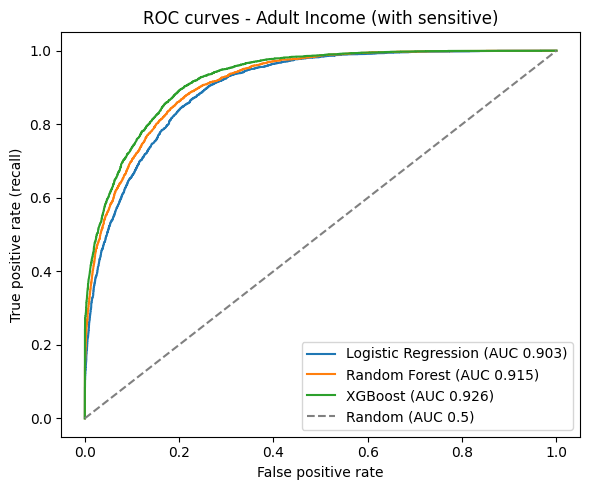

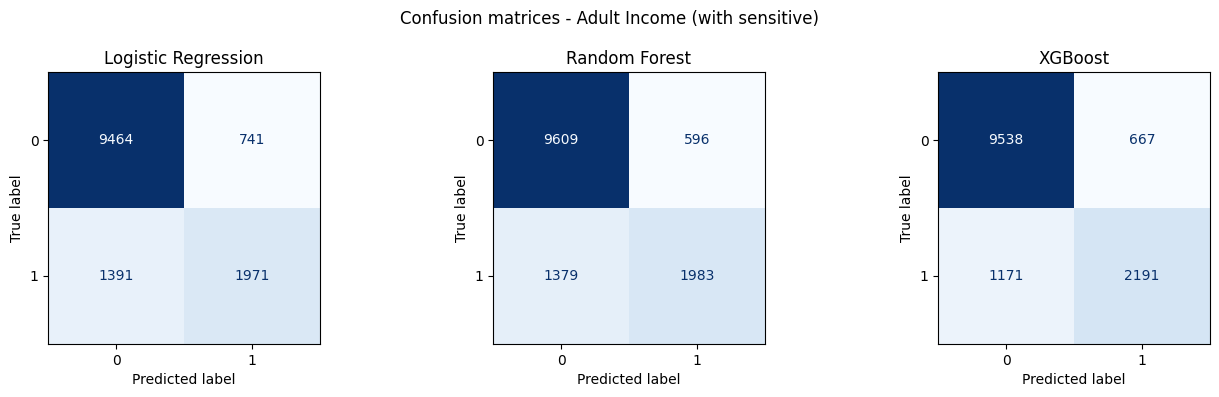

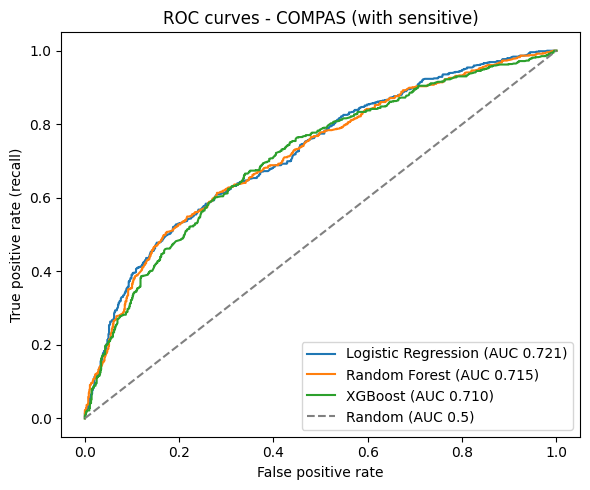

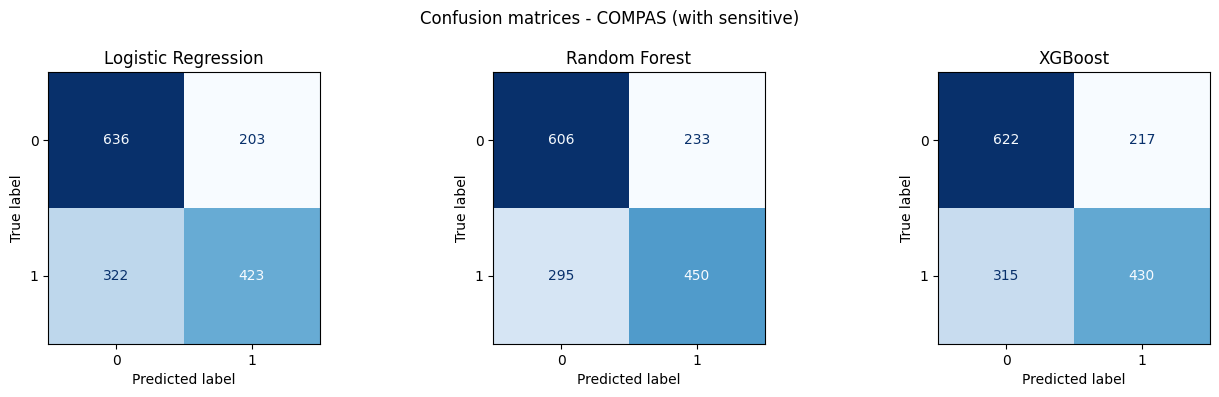

In [13]:
for name, (_, split) in prepared.items():
    evaluate.save_performance_figures(fitted[name], split, name)
    display(evaluate.plot_roc_curves(fitted[name], split, name, "with_sensitive"))
    display(evaluate.plot_confusion_matrices(fitted[name], split, name, "with_sensitive"))

## 5. Fairness of the predictions - RQ1 (`src/fairness.py`)

### 5.1 The metrics
**What:** fairlearn's `MetricFrame` computes per group: accuracy, selection rate (share predicted positive), true
positive rate and false positive rate. From these:

| Metric | Meaning | Fair value |
|---|---|---|
| Demographic parity (DP) difference | gap in selection rates | 0 |
| DP ratio | smaller / larger selection rate (below 0.8 fails the four-fifths rule) | 1 |
| Equal opportunity (EO) difference | gap in true positive rates | 0 |
| Equalized odds difference | larger of the TPR and FPR gaps | 0 |

**Viva tip:** "Demographic parity ignores who really is positive; equal opportunity compares only truly positive
people, so it does not punish a model for different base rates."

In [14]:
show_source(fairness.fairness_metrics)

```python
def fairness_metrics(
    y_true: pd.Series | np.ndarray, y_pred: np.ndarray, groups: pd.Series
) -> dict[str, float]:
    """The four summary fairness numbers for one binary sensitive attribute.

    Equal opportunity difference is the between-group difference of the TPR
    column of the MetricFrame - exactly its definition.
    """
    y_true, y_pred, groups = np.asarray(y_true), np.asarray(y_pred), np.asarray(groups)
    frame = group_metric_frame(y_true, y_pred, groups)
    return {
        "dp_difference": demographic_parity_difference(y_true, y_pred, sensitive_features=groups),
        "dp_ratio": demographic_parity_ratio(y_true, y_pred, sensitive_features=groups),
        "eo_difference": float(frame.difference(method="between_groups")["true_positive_rate"]),
        "eodds_difference": equalized_odds_difference(y_true, y_pred, sensitive_features=groups),
    }

```

### 5.2 Compute fairness for every dataset x setting x model x attribute
**What:** 24 comparisons, each with a plain-English sentence generated from the numbers.

**Look for:** every DP ratio below 0.8; sentences such as *"Logistic Regression predicts re-offending within two years
for 50% of African-American defendants but 23% of Caucasian defendants"*.

In [15]:
results_fair = {name: fairness.run_fairness(name, fitted[name], split, loaded.metadata)
                for name, (loaded, split) in prepared.items()}
fair = pd.concat([r[0] for r in results_fair.values()], ignore_index=True)
fair_groups = pd.concat([r[1] for r in results_fair.values()], ignore_index=True)
fairness.save_fairness_tables(fair, fair_groups)
display(fair[["dataset", "setting", "model", "attribute", "dp_difference", "dp_ratio", "eo_difference",
              "eodds_difference"]].round(3))
print(f"{int((fair['dp_ratio'] < 0.8).sum())} of {len(fair)} combinations fail the four-fifths rule.\n")
for row in fair[fair["setting"] == "with_sensitive"].to_dict("records"):
    print("-", row["interpretation"])

16:09:55 | INFO    | src.fairness | Wrote fairness.csv (24 rows) and fairness_by_group.csv (48 rows).


,dataset,setting,model,attribute,dp_difference,dp_ratio,eo_difference,eodds_difference
0,adult,with_sensitive,logistic_regression,sex,0.180,0.303,0.124,0.124
1,adult,with_sensitive,logistic_regression,race,0.088,0.583,0.062,0.062
2,adult,with_sensitive,random_forest,sex,0.176,0.289,0.132,0.132
3,adult,with_sensitive,random_forest,race,0.087,0.568,0.062,0.062
4,adult,with_sensitive,xgboost,sex,0.181,0.330,0.080,0.080
5,adult,with_sensitive,xgboost,race,0.091,0.592,0.050,0.050
6,adult,without_sensitive,logistic_regression,sex,0.173,0.323,0.096,0.096
7,adult,without_sensitive,logistic_regression,race,0.079,0.622,0.034,0.034
8,adult,without_sensitive,random_forest,sex,0.176,0.291,0.131,0.131
9,adult,without_sensitive,random_forest,race,0.080,0.605,0.034,0.034


24 of 24 combinations fail the four-fifths rule.

- Logistic Regression predicts >50K for 26% of men but 8% of women (demographic parity difference 0.18).
- Logistic Regression predicts >50K for 21% of White people but 12% of Non-White people (demographic parity difference 0.09).
- Random Forest predicts >50K for 25% of men but 7% of women (demographic parity difference 0.18).
- Random Forest predicts >50K for 20% of White people but 11% of Non-White people (demographic parity difference 0.09).
- XGBoost predicts >50K for 27% of men but 9% of women (demographic parity difference 0.18).
- XGBoost predicts >50K for 22% of White people but 13% of Non-White people (demographic parity difference 0.09).
- Logistic Regression predicts re-offending within two years for 50% of African-American defendants but 23% of Caucasian defendants (demographic parity difference 0.27).
- Logistic Regression predicts re-offending within two years for 46% of male defendants but 12% of female defendants (demog

### 5.3 Per-group charts, amplification and unawareness
**What:** per-group bars (blue = privileged, orange = unprivileged); then two analyses:
* **Amplification:** is the model's gap bigger than the real gap in the data (base-rate difference)?
* **Unawareness:** how much of the gap disappears when sex and race are removed from the inputs?

**Look for:** COMPAS models roughly double the race gap in the data; on Adult, removing the sensitive features removes
only about 2% of the sex gap - other features (proxies) still carry it.

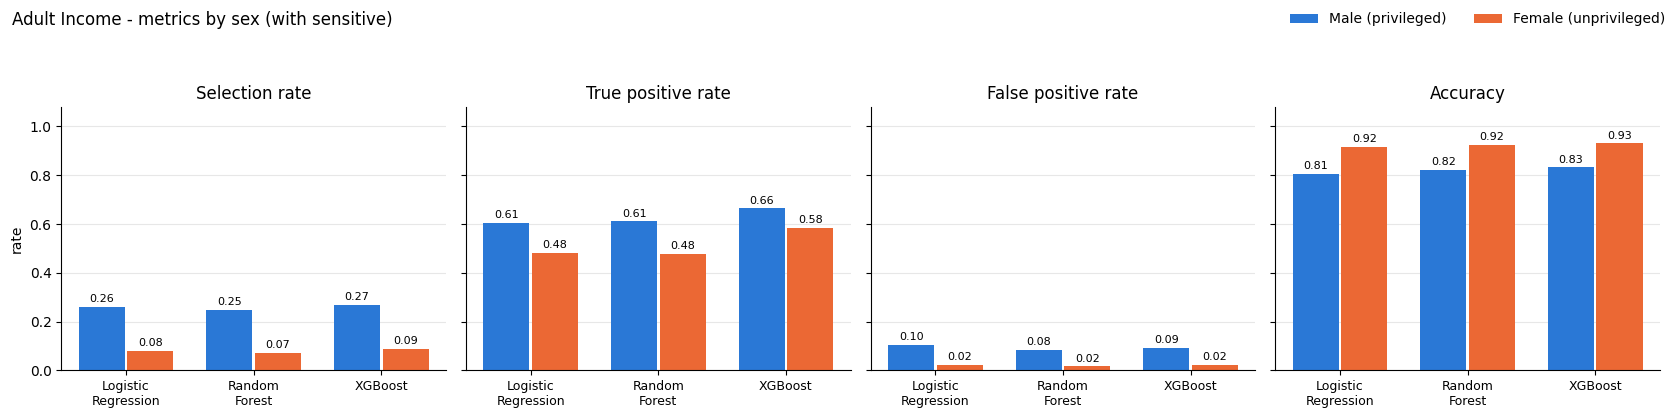

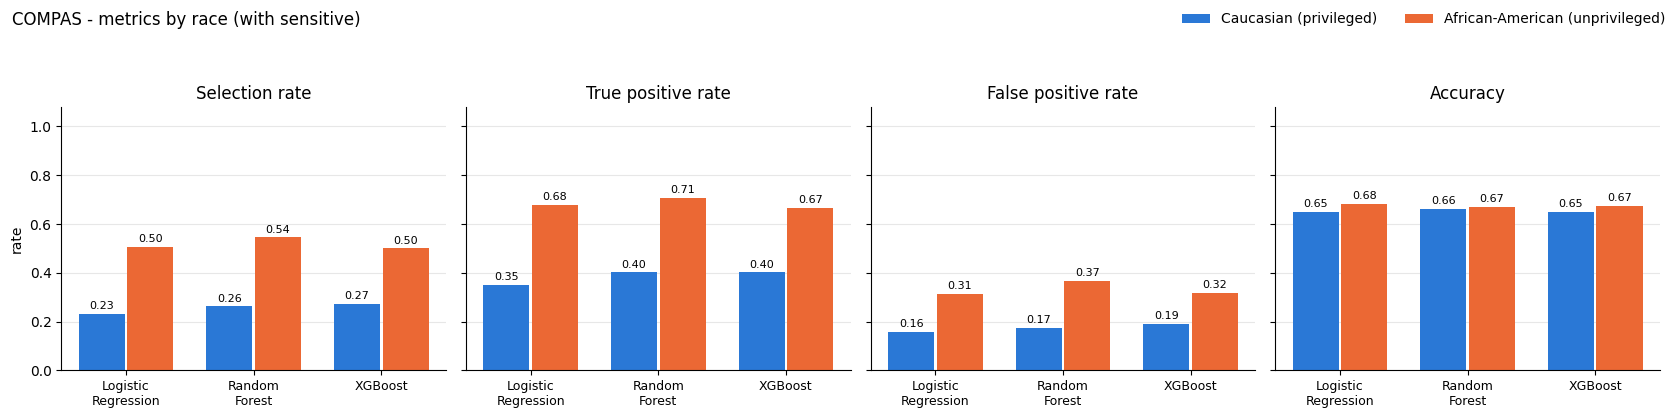

,dataset,model,attribute,base_rate_difference,dp_difference,model_gap_minus_data_gap
0,adult,logistic_regression,sex,0.190,0.180,-0.010
1,adult,logistic_regression,race,0.103,0.088,-0.015
2,adult,random_forest,sex,0.190,0.176,-0.015
3,adult,random_forest,race,0.103,0.087,-0.016
4,adult,xgboost,sex,0.190,0.181,-0.010
5,adult,xgboost,race,0.103,0.091,-0.012
12,compas,logistic_regression,race,0.133,0.272,0.140
13,compas,logistic_regression,sex,0.118,0.338,0.220
14,compas,random_forest,race,0.133,0.283,0.150
15,compas,random_forest,sex,0.118,0.303,0.186


setting                                with_sensitive  without_sensitive  share_of_gap_removed
dataset attribute model                                                                       
adult   race      logistic_regression           0.088              0.079                 0.103
                  random_forest                 0.087              0.080                 0.088
                  xgboost                       0.091              0.086                 0.059
        sex       logistic_regression           0.180              0.173                 0.041
                  random_forest                 0.176              0.176                -0.001
                  xgboost                       0.181              0.174                 0.034
compas  race      logistic_regression           0.272              0.220                 0.192
                  random_forest                 0.283              0.239                 0.156
                  xgboost                       0.226              0.217                 0.040
        sex       logistic_regression           0.338              0.174                 0.486
                  random_forest                 0.303              0.151                 0.502
                  xgboost                       0.279              0.147                 0.472

In [16]:
for name, (loaded, _) in prepared.items():
    display(fairness.plot_group_metrics(fair_groups, loaded.metadata, "with_sensitive",
                                        loaded.metadata.primary_sensitive))

amp = fair[fair["setting"] == "with_sensitive"][["dataset", "model", "attribute", "base_rate_difference",
                                                 "dp_difference"]].copy()
amp["model_gap_minus_data_gap"] = amp["dp_difference"] - amp["base_rate_difference"]
display(amp.round(3))

wide = fair.pivot_table(index=["dataset", "attribute", "model"], columns="setting", values="dp_difference")
wide["share_of_gap_removed"] = 1 - wide["without_sensitive"] / wide["with_sensitive"]
display(wide.round(3))

## 6. Explanations per group (`src/explain.py`)

### 6.1 Which people are explained?
**What:** for every sensitive attribute and group, up to 200 test people are sampled for SHAP; the **first 100 of the
same people** are explained with LIME.

**Why:** sampling per group guarantees enough people from small groups (e.g. Non-White, female defendants). The
sample depends only on the test split and the seed, so every model and both settings explain the **same people**.

In [17]:
show_source(explain.sample_instances)

```python
def sample_instances(
    split: SplitData, metadata: DatasetMetadata, settings: ExplainSettings
) -> pd.DataFrame:
    """Choose which test rows to explain.

    Returns one row per sampled test instance (index = original row id) with,
    for every sensitive attribute A:
      group_A    - the instance's group label for A
      in_shap_A  - True if sampled for the SHAP comparison of A
      in_lime_A  - True if sampled for the LIME comparison of A

    Sampling per group (instead of a random sample of the whole test set)
    guarantees enough instances from small groups such as Non-White or
    female defendants. If a group is smaller than n, all its rows are used.
    """
    shap_ids: dict[str, set] = {}
    lime_ids: dict[str, set] = {}
    for attribute in metadata.sensitive_attributes:
        rng = np.random.default_rng(settings.seed)
        shap_ids[attribute], lime_ids[attribute] = set(), set()
        for _, index in sorted(split.s_test.groupby(attribute).groups.items()):
            shuffled = rng.permutation(np.asarray(index))
            shap_ids[attribute].update(shuffled[: settings.shap_n_per_group])
            # The first lime_n of the same shuffled order -> LIME subset of SHAP.
            lime_ids[attribute].update(shuffled[: settings.lime_n_per_group])

    all_ids = sorted(set().union(*shap_ids.values()))
    instances = pd.DataFrame(index=pd.Index(all_ids, name="instance_id"))
    for attribute in metadata.sensitive_attributes:
        instances[f"group_{attribute}"] = split.s_test.loc[all_ids, attribute].to_numpy()
        instances[f"in_shap_{attribute}"] = instances.index.isin(list(shap_ids[attribute]))
        instances[f"in_lime_{attribute}"] = instances.index.isin(list(lime_ids[attribute]))
    return instances

```

### 6.2 SHAP and LIME
**What:**
* **SHAP** - `TreeExplainer` for Random Forest and XGBoost (exact Shapley values from the trees), `LinearExplainer`
  for Logistic Regression. `positive_class_shap` handles Random Forest returning values for both classes.
* **LIME** - perturbs each person 1,000 times, asks the model for probabilities and fits a weighted linear model. Its
  R-squared (`exp.score`) is the **fidelity**: how well the explanation imitates the model near this person. One-hot
  columns are declared categorical so LIME perturbs them correctly.

**Why the cache:** explanations take minutes, so they are saved in `results/cache/`. The cache stores the model's
predicted probabilities; if a model changes, the stale cache is detected and recomputed.

**Note:** this is the slowest block (Random Forest SHAP and 1,000-sample LIME). Expect several minutes on Colab.

In [18]:
show_source(explain.positive_class_shap)
show_source(explain.lime_values)

```python
def positive_class_shap(values: np.ndarray | list) -> np.ndarray:
    """Return SHAP values for the positive class as an (n, n_features) array.

    Why this is needed: shap returns different shapes per model type.
      * XGBoost and LinearExplainer: one (n, f) array - a binary model has a
        single output (log-odds of class 1), so there is nothing to select.
      * scikit-learn Random Forest: it predicts BOTH class probabilities, so
        shap returns one set of values per class - a list [class0, class1] in
        older shap versions, a 3-D array (n, f, 2) in newer ones. Class 0
        values are exactly minus the class 1 values, so we keep class 1.
    """
    if isinstance(values, list):
        return np.asarray(values[1])
    values = np.asarray(values)
    if values.ndim == 3:
        return values[:, :, 1]
    return values

```

```python
def lime_values(
    pipeline: Pipeline,
    X_train: pd.DataFrame,
    X_explain: pd.DataFrame,
    num_samples: int,
    seed: int,
    explainer: LimeTabularExplainer | None = None,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """LIME weights (n, n_transformed), fidelity (n,) and local predictions (n,).

    For each instance LIME samples `num_samples` perturbed rows around it,
    asks the model for their probabilities (predict_fn = the classifier's
    predict_proba on transformed rows), and fits a weighted linear model.

    exp.score is the R-squared of that linear surrogate on the perturbed
    samples (weighted by proximity). We call it FIDELITY: how well the simple
    explanation imitates the model near this person. Low fidelity means the
    explanation should be trusted less. Note it is measured on LIME's own
    synthetic neighbourhood, not on real data.

    An existing `explainer` can be passed in: its random generator then
    continues from where it stopped instead of restarting at `seed`. The
    stability module uses this, so explaining the same row twice gives two
    genuinely independent LIME runs (LIME's own randomness).
    """
    if explainer is None:
        explainer = make_lime_explainer(pipeline, X_train, seed)
    model = pipeline.named_steps[MODEL_STEP]
    X_t = pipeline.named_steps[PREPROCESSOR_STEP].transform(X_explain)
    n_features = X_t.shape[1]
    weights = np.zeros_like(X_t, dtype=float)
    fidelity = np.zeros(len(X_t))
    local_pred = np.zeros(len(X_t))
    for i, row in enumerate(X_t):
        exp = explainer.explain_instance(
            row, model.predict_proba, num_features=n_features,
            num_samples=num_samples, labels=(1,),
        )
        for feature_idx, weight in exp.as_map()[1]:
            weights[i, feature_idx] = weight
        fidelity[i] = exp.score
        local_pred[i] = np.ravel(exp.local_pred)[0]
    return weights, fidelity, local_pred

```

In [19]:
explanations = {}
for name, (loaded, split) in prepared.items():
    explanations[name] = explain.run_explanations(name, fitted[name], split, loaded.metadata, EXPLAIN_SETTINGS)
instances, tables = explanations["adult"]
tidy = explain.tidy_explanations(tables[("with_sensitive", "xgboost")], instances, "sex")
display(tidy.head(8))
print(tidy.groupby(["method", "group"])["instance_id"].nunique().rename("people explained"))

16:09:56 | INFO    | src.explain | Using cached explanations explanations_adult_with_sensitive_logistic_regression_s200_l100_n1000.csv


16:09:56 | INFO    | src.explain | Using cached explanations explanations_adult_with_sensitive_random_forest_s200_l100_n1000.csv


16:09:56 | INFO    | src.explain | Using cached explanations explanations_adult_with_sensitive_xgboost_s200_l100_n1000.csv


16:09:56 | INFO    | src.explain | Using cached explanations explanations_adult_without_sensitive_logistic_regression_s200_l100_n1000.csv


16:09:56 | INFO    | src.explain | Using cached explanations explanations_adult_without_sensitive_random_forest_s200_l100_n1000.csv


16:09:56 | INFO    | src.explain | Using cached explanations explanations_adult_without_sensitive_xgboost_s200_l100_n1000.csv


... (4 outputs left out)

16:09:56 | INFO    | src.explain | Using cached explanations explanations_compas_without_sensitive_random_forest_s200_l100_n1000.csv


16:09:56 | INFO    | src.explain | Using cached explanations explanations_compas_without_sensitive_xgboost_s200_l100_n1000.csv


,instance_id,group,method,original_feature,attribution
0,120,Male,shap,age,0.437802
1,137,Male,shap,age,0.774753
2,241,Female,shap,age,0.346745
3,363,Female,shap,age,1.415582
4,420,Female,shap,age,1.475965
5,449,Male,shap,age,4.353229
6,462,Male,shap,age,0.075239
7,602,Male,shap,age,0.608279


method  group 
lime    Female    100
        Male      100
shap    Female    200
        Male      200
Name: people explained, dtype: int64


## 7. Comparing explanations across groups - RQ2 (`src/compare.py`)

### 7.1 The measures
* **Sensitive reliance** - per person, the share of total absolute attribution given to the sensitive feature.
  Shares make SHAP and LIME comparable although their units differ.
* **Proxy reliance** - the same share for the 3 features with the highest **mutual information** with the sensitive
  attribute (training data).
* **Rank agreement** - Spearman rho and Kendall tau between the two groups' feature rankings (1 = identical order),
  Jaccard overlap of the top-5 features, and a **bootstrap 95% CI** for rho (1,000 resamples).
* **Fidelity gap** (LIME) - difference in mean fidelity between the groups.

In [20]:
show_source(compare.reliance_share)
show_source(compare.bootstrap_spearman_ci)

```python
def reliance_share(attributions: pd.DataFrame, features: list[str]) -> pd.Series:
    """Share of each row's total absolute attribution that goes to `features`.

    Features missing from the table (e.g. the sensitive feature in the
    'without sensitive' setting) contribute nothing. Rows whose attributions
    are all zero get share 0 instead of a division by zero.
    """
    present = [f for f in features if f in attributions.columns]
    total = attributions.sum(axis=1)
    part = attributions[present].sum(axis=1) if present else pd.Series(0.0, index=attributions.index)
    return (part / total.where(total > 0)).fillna(0.0)

```

```python
def bootstrap_spearman_ci(
    a: np.ndarray, b: np.ndarray, n_boot: int = config.N_BOOTSTRAP,
    seed: int = config.SEED, level: float = 0.95,
) -> tuple[float, float]:
    """Percentile bootstrap CI for Spearman rho between two groups' mean importances.

    a, b: per-instance attribution matrices (instances x features) of the two
    groups. Each resample draws instances WITH replacement within each group,
    recomputes both groups' mean importances and their Spearman rho. The
    middle 95% of the rho values is the CI. A wide interval means the
    ranking comparison is uncertain (e.g. small groups).
    """
    rng = np.random.default_rng(seed)
    rhos = np.empty(n_boot)
    for i in range(n_boot):
        mean_a = a[rng.integers(0, len(a), len(a))].mean(axis=0)
        mean_b = b[rng.integers(0, len(b), len(b))].mean(axis=0)
        rhos[i] = spearmanr(mean_a, mean_b).statistic
    tail = (1 - level) / 2 * 100
    low, high = np.nanpercentile(rhos, [tail, 100 - tail])
    return float(low), float(high)

```

### 7.2 Run all 48 comparisons
**What:** 2 datasets x 2 settings x 3 models x 2 methods x 2 attributes.

**Look for:** the automatically chosen proxies - Adult/sex: relationship, marital-status, occupation;
COMPAS/race: age, priors_count, juv_fel_count.

In [21]:
parts = {name: compare.run_comparison(split, loaded.metadata, *explanations[name], N_BOOT)
         for name, (loaded, split) in prepared.items()}
results_cmp = {key: pd.concat([p[key] for p in parts.values()], ignore_index=True) for key in parts["adult"]}
compare.save_comparison_tables(results_cmp)
comparison, per_instance, importance = results_cmp["comparison"], results_cmp["per_instance"], results_cmp["importance"]
proxies = results_cmp["proxies"]
display(proxies[proxies["selected"]][["dataset", "attribute", "feature", "mutual_information"]].round(4))
display(comparison[["dataset", "setting", "model", "method", "attribute", "sensitive_reliance_privileged",
                    "sensitive_reliance_unprivileged", "proxy_reliance_privileged", "proxy_reliance_unprivileged",
                    "spearman_rho", "spearman_ci_low", "spearman_ci_high", "jaccard_top5", "fidelity_gap"]].round(3))

16:09:57 | INFO    | src.compare | adult | proxies for sex: ['relationship', 'marital-status', 'occupation']


16:09:57 | INFO    | src.compare | adult | proxies for race: ['native-country', 'relationship', 'hours-per-week']


16:10:23 | INFO    | src.compare | compas | proxies for race: ['age', 'priors_count', 'juv_fel_count']


16:10:23 | INFO    | src.compare | compas | proxies for sex: ['priors_count', 'juv_misd_count', 'age']


16:10:48 | INFO    | src.compare | Wrote explanation_comparison.csv (48 rows).


16:10:48 | INFO    | src.compare | Wrote per_instance_reliance.csv (14400 rows).


16:10:48 | INFO    | src.compare | Wrote global_importance.csv (864 rows).


16:10:48 | INFO    | src.compare | Wrote proxies.csv (32 rows).


,dataset,attribute,feature,mutual_information
0,adult,sex,relationship,0.2709
1,adult,sex,marital-status,0.1161
2,adult,sex,occupation,0.1033
10,adult,race,native-country,0.0471
11,adult,race,relationship,0.0130
12,adult,race,hours-per-week,0.0086
20,compas,race,age,0.0285
21,compas,race,priors_count,0.0161
22,compas,race,juv_fel_count,0.0110
26,compas,sex,priors_count,0.0119


,dataset,setting,model,method,attribute,sensitive_reliance_privileged,sensitive_reliance_unprivileged,proxy_reliance_privileged,proxy_reliance_unprivileged,spearman_rho,spearman_ci_low,spearman_ci_high,jaccard_top5,fidelity_gap
0,adult,with_sensitive,logistic_regression,shap,sex,0.058,0.125,0.556,0.544,0.937,0.881,0.972,0.667,NaN
1,adult,with_sensitive,logistic_regression,shap,race,0.025,0.146,0.173,0.158,0.713,0.643,0.748,0.667,NaN
2,adult,with_sensitive,logistic_regression,lime,sex,0.022,0.022,0.354,0.353,1.000,0.972,1.000,1.000,0.005
3,adult,with_sensitive,logistic_regression,lime,race,0.023,0.022,0.425,0.429,0.993,0.972,1.000,1.000,0.005
4,adult,with_sensitive,random_forest,shap,sex,0.029,0.056,0.551,0.585,0.979,0.937,0.986,1.000,NaN
5,adult,with_sensitive,random_forest,shap,race,0.004,0.024,0.261,0.266,0.979,0.951,0.993,1.000,NaN
6,adult,with_sensitive,random_forest,lime,sex,0.008,0.008,0.327,0.327,0.993,0.993,1.000,1.000,0.000
7,adult,with_sensitive,random_forest,lime,race,0.006,0.006,0.427,0.434,0.993,0.993,1.000,1.000,0.006
8,adult,with_sensitive,xgboost,shap,sex,0.017,0.063,0.467,0.484,0.958,0.881,0.958,1.000,NaN
9,adult,with_sensitive,xgboost,shap,race,0.004,0.035,0.142,0.144,0.958,0.902,0.965,1.000,NaN


### 7.3 Top features and reliance per group
**What:** for XGBoost on Adult (sex, with sensitive features): each group's top-10 features side by side, and box plots
of sensitive and proxy reliance.

**Look for:** with SHAP, `sex` gets a larger share for women than for men.

**Viva tip (important finding):** "SHAP measures each feature against an *average person*. The majority group (men,
67% of Adult) dominates that average, so women are further from it and their SHAP value for sex is larger. On COMPAS,
where the larger group is African-American, the gap reverses - part of a SHAP group gap reflects group size, not
unequal treatment."

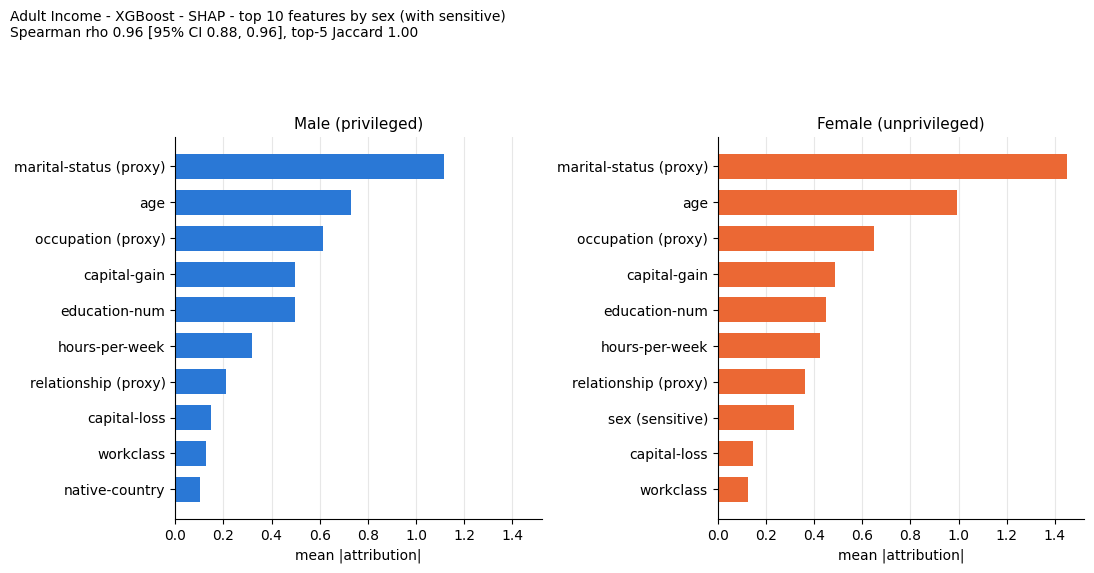

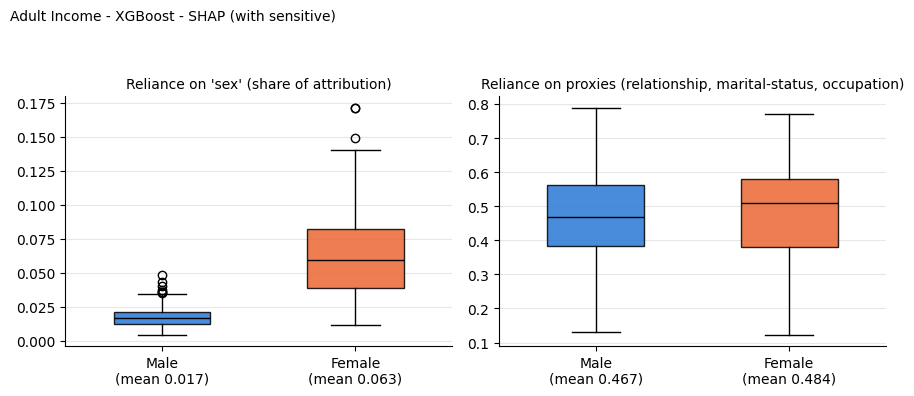

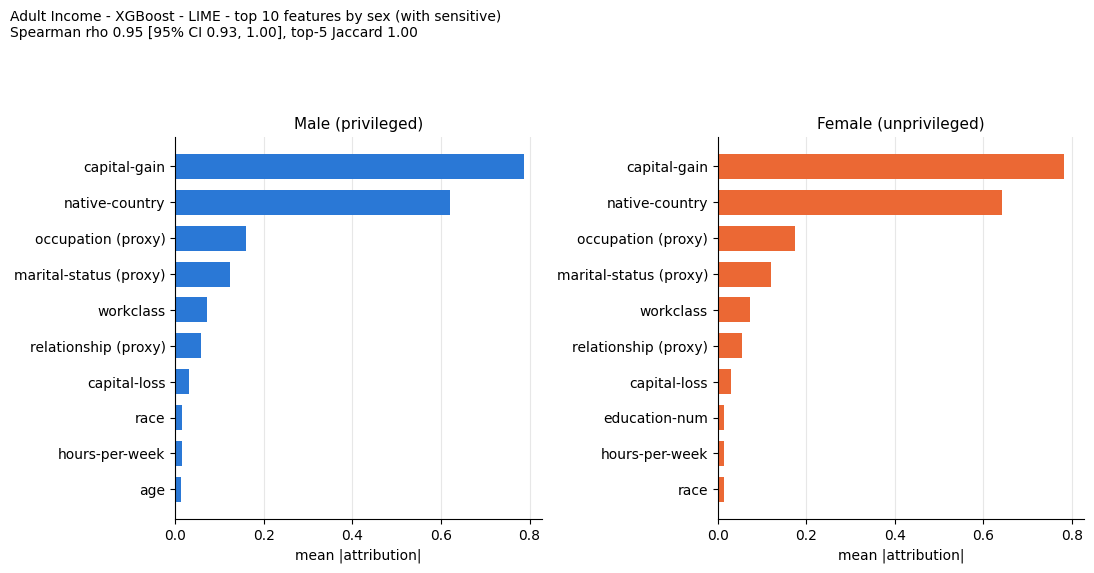

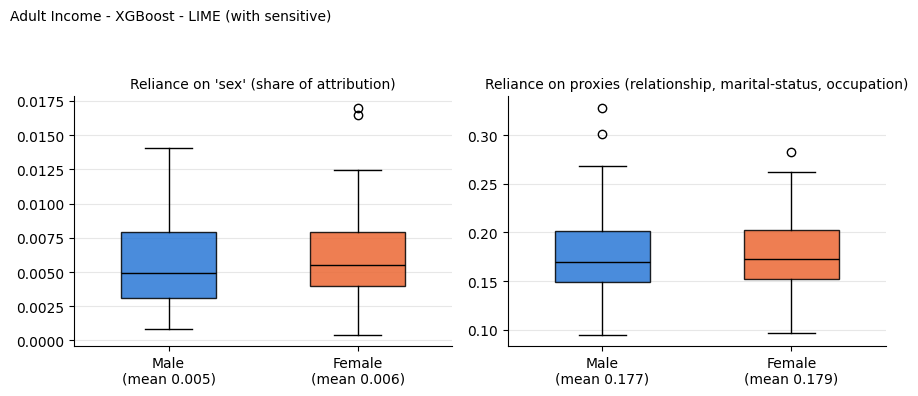

In [22]:
def pick(frame, **keys):
    mask = pd.Series(True, index=frame.index)
    for column, value in keys.items():
        mask &= frame[column] == value
    return frame[mask]

for method in config.XAI_METHODS:
    keys = dict(dataset="adult", setting="with_sensitive", model="xgboost", method=method, attribute="sex")
    row = pick(comparison, **keys).iloc[0].to_dict()
    display(compare.plot_top_features(pick(importance, **keys), row, row["proxies"].split(";")))
    display(compare.plot_reliance_boxes(pick(per_instance, **keys), row))

## 8. Statistical tests - RQ3 (`src/stats.py`)
**Hypotheses** (for every comparison and measure):
* **H0:** sensitive reliance / proxy reliance / LIME fidelity has the same distribution in both groups.
* **H1:** the distributions differ (two-sided).

**Why Mann-Whitney U:** the measures are bounded and skewed, so a t-test's normality assumption is doubtful;
Mann-Whitney compares ranks. **Rank-biserial r** is the effect size (-1 to 1). **Holm correction** controls false
positives across all tests of the run.

**Look for:** 17 of 96 tests significant after Holm - all for SHAP, none for LIME.

In [23]:
show_source(stats.mann_whitney)
show_source(stats.holm_adjust)

```python
def mann_whitney(x: np.ndarray | pd.Series, y: np.ndarray | pd.Series) -> dict[str, float]:
    """Two-sided Mann-Whitney U test between x and y, NaNs dropped.

    Returns U (for x), p_value, rank_biserial, n1 and n2. If either sample has
    fewer than 2 values the test is undefined and NaNs are returned. If all
    values are identical there is no difference at all: p = 1, r = 0.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x, y = x[~np.isnan(x)], y[~np.isnan(y)]
    n1, n2 = len(x), len(y)
    if n1 < 2 or n2 < 2:
        return {"u_statistic": np.nan, "p_value": np.nan, "rank_biserial": np.nan, "n1": n1, "n2": n2}
    if np.ptp(np.concatenate([x, y])) == 0:
        return {"u_statistic": n1 * n2 / 2, "p_value": 1.0, "rank_biserial": 0.0, "n1": n1, "n2": n2}
    result = mannwhitneyu(x, y, alternative="two-sided")
    return {
        "u_statistic": float(result.statistic),
        "p_value": float(result.pvalue),
        "rank_biserial": rank_biserial(result.statistic, n1, n2),
        "n1": n1,
        "n2": n2,
    }

```

```python
def holm_adjust(p_values: np.ndarray | pd.Series) -> np.ndarray:
    """Holm step-down adjusted p-values (NaNs are kept and not counted).

    Sort the m p-values ascending; the i-th smallest (i = 1..m) is multiplied
    by (m - i + 1). A running maximum keeps the adjusted values in the same
    order as the raw ones, and values are capped at 1. Rejecting where the
    adjusted p < alpha is the Holm procedure.
    """
    p = np.asarray(p_values, dtype=float)
    adjusted = np.full_like(p, np.nan)
    valid = np.where(~np.isnan(p))[0]
    m = len(valid)
    if m == 0:
        return adjusted
    order = valid[np.argsort(p[valid])]
    running_max = 0.0
    for rank, idx in enumerate(order):
        value = min(1.0, (m - rank) * p[idx])
        running_max = max(running_max, value)
        adjusted[idx] = running_max
    return adjusted

```

In [24]:
tests = stats.run_stat_tests(per_instance)
stats.save_stat_tests(tests)
display(tests.groupby(["measure", "method"]).agg(tests=("p_value", "size"),
                                                significant_after_holm=("significant_holm", "sum")))
display(tests[tests["significant_holm"]][["dataset", "setting", "model", "method", "attribute", "measure",
                                         "mean_privileged", "mean_unprivileged", "p_holm",
                                         "rank_biserial"]].sort_values("p_holm").round(4))

16:10:49 | INFO    | src.stats | 96 tests: 21 significant before and 17 after Holm correction (alpha 0.05).


16:10:49 | INFO    | src.stats | Wrote stat_tests.csv (96 rows).


tests  significant_after_holm
measure            method                               
fidelity           lime       24                       0
proxy_reliance     lime       24                       0
                   shap       24                       5
sensitive_reliance lime       12                       0
                   shap       12                      12

,dataset,setting,model,method,attribute,measure,mean_privileged,mean_unprivileged,p_holm,rank_biserial
2,adult,with_sensitive,logistic_regression,shap,race,sensitive_reliance,0.0252,0.1461,0.0000,-1.0000
50,compas,with_sensitive,logistic_regression,shap,sex,sensitive_reliance,0.2329,0.0554,0.0000,0.9965
22,adult,with_sensitive,xgboost,shap,race,sensitive_reliance,0.0042,0.0345,0.0000,-0.9938
0,adult,with_sensitive,logistic_regression,shap,sex,sensitive_reliance,0.0578,0.1255,0.0000,-0.9806
12,adult,with_sensitive,random_forest,shap,race,sensitive_reliance,0.0044,0.0239,0.0000,-0.9718
20,adult,with_sensitive,xgboost,shap,sex,sensitive_reliance,0.0175,0.0633,0.0000,-0.9186
70,compas,with_sensitive,xgboost,shap,sex,sensitive_reliance,0.1909,0.0584,0.0000,0.8326
60,compas,with_sensitive,random_forest,shap,sex,sensitive_reliance,0.2077,0.0618,0.0000,0.8255
10,adult,with_sensitive,random_forest,shap,sex,sensitive_reliance,0.0294,0.0559,0.0000,-0.7186
48,compas,with_sensitive,logistic_regression,shap,race,sensitive_reliance,0.0563,0.0344,0.0000,0.6609


### 8.1 Plain-English interpretation
**What:** `interpret_comparison` writes one paragraph per comparison from its numbers and tests (shown for the
primary attribute of each dataset, with sensitive features).

In [25]:
for name, (loaded, _) in prepared.items():
    attribute = loaded.metadata.primary_sensitive
    for row in pick(comparison, dataset=name, setting="with_sensitive", attribute=attribute).to_dict("records"):
        t = pick(tests, dataset=name, setting="with_sensitive", model=row["model"], method=row["method"],
                 attribute=attribute)
        print(f"[{name} | {row['model']} | {row['method']}]\n{compare.interpret_comparison(row, t)}\n")

[adult | logistic_regression | shap]
For Logistic Regression, SHAP assigns on average 5.8% of the total attribution to 'sex' for Male instances and 12.5% for Female instances. The proxy features (relationship, marital-status, occupation) receive 55.6% (Male) vs 54.4% (Female). The two groups' feature rankings are very similar (Spearman rho 0.94, 95% CI 0.88 to 0.97; 67% overlap in the top 5 features). After Holm correction the group difference is statistically significant for: sensitive reliance (adjusted p = 1.42e-62).

[adult | logistic_regression | lime]
For Logistic Regression, LIME assigns on average 2.2% of the total attribution to 'sex' for Male instances and 2.2% for Female instances. The proxy features (relationship, marital-status, occupation) receive 35.4% (Male) vs 35.3% (Female). The two groups' feature rankings are very similar (Spearman rho 1.00, 95% CI 0.97 to 1.00; 100% overlap in the top 5 features). LIME's local fidelity is 0.75 for Male and 0.75 for Female (gap +0.0

## 9. Trade-off and Pareto analysis - RQ4 (`src/compare.py`)
**What:** for each dataset, setting and attribute, rows = model x XAI method, columns = accuracy, F1, DP difference,
EO difference, Spearman rho between groups and |fidelity gap|. A row is **Pareto-optimal** if no other row is at least
as good on every column and better on one.

**Why no weighted score:** any weighting would be arbitrary; the Pareto set shows the real compromises. SHAP is exact,
so its fidelity gap is shown as missing and counted as 0 in the check.

In [26]:
show_source(compare.pareto_optimal)
tradeoff = compare.build_tradeoff(performance, fair, comparison)
compare.save_tradeoff(tradeoff)
display(tradeoff[tradeoff["setting"] == "with_sensitive"].round(3))
print(f"{int(tradeoff['is_pareto'].sum())} of {len(tradeoff)} rows are Pareto-optimal.")

```python
def pareto_optimal(frame: pd.DataFrame, directions: dict[str, str] = TRADEOFF_DIRECTIONS) -> pd.Series:
    """True for rows that no other row dominates.

    Row B dominates row A if B is at least as good as A on every column and
    strictly better on at least one (the standard Pareto definition). Columns
    where either row is NaN (fidelity gap for SHAP rows) are skipped for that
    pair. No weighted score is used: Pareto-optimal rows are the "best
    compromises", and choosing among them is a value judgement.
    """
    signs = np.array([1.0 if directions[c] == "max" else -1.0 for c in directions])
    values = frame[list(directions)].to_numpy(dtype=float) * signs  # now "bigger is better"
    optimal = np.ones(len(frame), dtype=bool)
    for i in range(len(frame)):
        for j in range(len(frame)):
            if i == j:
                continue
            both = ~np.isnan(values[i]) & ~np.isnan(values[j])
            if not both.any():
                continue
            vi, vj = values[i][both], values[j][both]
            if np.all(vj >= vi) and np.any(vj > vi):
                optimal[i] = False
                break
    return pd.Series(optimal, index=frame.index)

```

16:10:49 | INFO    | src.compare | Wrote tradeoff.csv (48 rows, 37 Pareto-optimal).


,dataset,setting,model,method,attribute,accuracy,f1,dp_difference,eo_difference,spearman_rho,fidelity_gap_abs,is_pareto
0,adult,with_sensitive,logistic_regression,shap,sex,0.843,0.649,0.180,0.124,0.937,NaN,True
1,adult,with_sensitive,logistic_regression,shap,race,0.843,0.649,0.088,0.062,0.713,NaN,True
2,adult,with_sensitive,logistic_regression,lime,sex,0.843,0.649,0.180,0.124,1.000,0.005,True
3,adult,with_sensitive,logistic_regression,lime,race,0.843,0.649,0.088,0.062,0.993,0.005,True
4,adult,with_sensitive,random_forest,shap,sex,0.854,0.668,0.176,0.132,0.979,NaN,True
5,adult,with_sensitive,random_forest,shap,race,0.854,0.668,0.087,0.062,0.979,NaN,True
6,adult,with_sensitive,random_forest,lime,sex,0.854,0.668,0.176,0.132,0.993,0.000,True
7,adult,with_sensitive,random_forest,lime,race,0.854,0.668,0.087,0.062,0.993,0.006,True
8,adult,with_sensitive,xgboost,shap,sex,0.865,0.705,0.181,0.080,0.958,NaN,True
9,adult,with_sensitive,xgboost,shap,race,0.865,0.705,0.091,0.050,0.958,NaN,True


37 of 48 rows are Pareto-optimal.


## 10. Bias mitigation (`src/mitigation.py`)
**What:** retrains Logistic Regression with fairlearn's **ExponentiatedGradient** under a **demographic-parity**
constraint on the primary attribute (Adult: sex, COMPAS: race), then compares before vs after: performance, fairness
and LIME explanations on the same people.

**Why these details:**
* ExponentiatedGradient returns a **randomised mixture** of Logistic Regressions; its fairness guarantee holds for the
  random predictions, so accuracy, F1 and fairness use them (seeded). ROC-AUC and LIME use the expected probability.
* Only LIME is used: the mixture is neither one tree nor one linear model, so SHAP's Tree/Linear explainers do not apply.

**Look for:** COMPAS race gap 0.272 -> 0.023 with accuracy 0.669 -> 0.647; on Adult the sex gap almost disappears but
the equal-opportunity gap grows (0.124 -> 0.334).

```python
class MitigatedClassifier:
    """Adapter giving a fitted ExponentiatedGradient a predict_proba method.

    ExponentiatedGradient.predict() is RANDOMISED (it picks one of its
    Logistic Regressions at random for every row). For explanations and
    ROC-AUC we need deterministic probabilities, i.e. the expected
    prediction of the mixture. fairlearn computes exactly this in
    `_pmf_predict` (weighted average of the members' predictions). It is a
    private method (leading underscore), so a future fairlearn version could
    rename it; we pin fairlearn==0.12.0 in requirements.txt for that reason.
    """

    def __init__(self, mitigator: ExponentiatedGradient) -> None:
        self.mitigator = mitigator
        self.classes_ = np.array([0, 1])

    def fit(self, X: np.ndarray, y: np.ndarray, sensitive_features: np.ndarray) -> "MitigatedClassifier":
        """Fit the wrapped mitigator (lets the adapter act as a final Pipeline step)."""
        self.mitigator.fit(X, y, sensitive_features=sensitive_features)
        return self

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        """Expected class probabilities of the randomised mixture, shape (n, 2)."""
        return np.asarray(self.mitigator._pmf_predict(X))  # private fairlearn API, see class docstring

    def predict(self, X: np.ndarray) -> np.ndarray:
        """Randomised predictions of the mixture (seeded, so reproducible)."""
        return self.mitigator.predict(X, random_state=config.SEED)

```

16:10:50 | INFO    | src.mitigation | Mitigating adult | with_sensitive | constraint: demographic parity on sex


16:10:54 | INFO    | src.mitigation | Mitigator fitted: 2 Logistic Regressions in the mixture.


16:10:54 | INFO    | src.explain | Using cached explanations explanations_adult_with_sensitive_logistic_regression_s200_l100_n1000.csv


16:10:56 | INFO    | src.explain | Using cached explanations explanations_adult_with_sensitive_logistic_regression_mitigated_s200_l100_n1000.csv


16:10:58 | INFO    | src.mitigation | Mitigating adult | without_sensitive | constraint: demographic parity on sex


... (10 outputs left out)

16:11:12 | INFO    | src.explain | Using cached explanations explanations_compas_without_sensitive_logistic_regression_mitigated_s200_l100_n1000.csv


16:11:13 | INFO    | src.stats | 40 tests: 0 significant before and 0 after Holm correction (alpha 0.05).


16:11:13 | INFO    | src.mitigation | Wrote mitigation.csv (16 rows) and mitigation_tests.csv (40 rows).


,dataset,setting,stage,accuracy,roc_auc,dp_difference,eo_difference,spearman_rho,fidelity_gap
0,adult,with_sensitive,before,0.843,0.903,0.180,0.124,1.000,0.005
2,adult,with_sensitive,after,0.829,0.721,0.003,0.334,1.000,0.002
4,adult,without_sensitive,before,0.843,0.902,0.173,0.096,1.000,0.003
6,adult,without_sensitive,after,0.827,0.717,0.002,0.305,1.000,-0.000
8,compas,with_sensitive,before,0.669,0.721,0.272,0.328,0.952,-0.041
10,compas,with_sensitive,after,0.647,0.683,0.023,0.058,0.810,-0.010
12,compas,without_sensitive,before,0.665,0.723,0.220,0.262,0.943,-0.032
14,compas,without_sensitive,after,0.562,0.531,0.054,0.102,0.829,-0.002


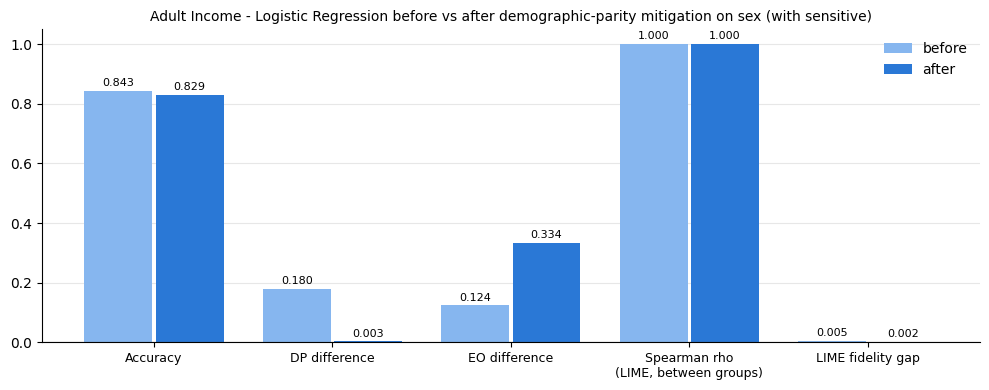

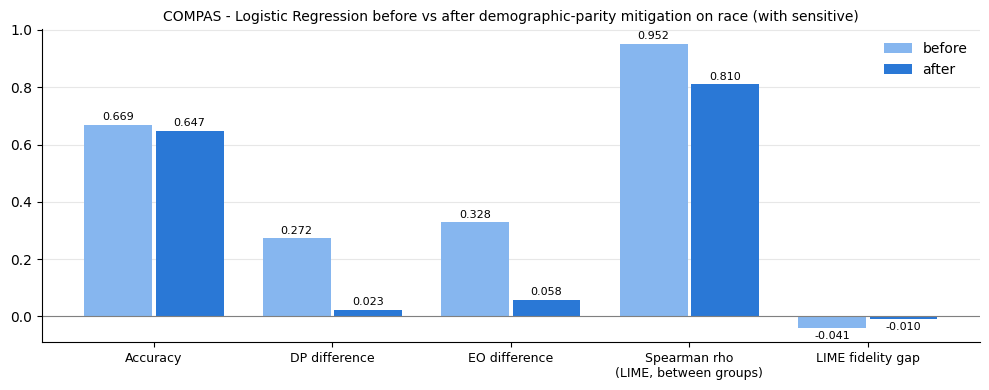

In [27]:
show_source(mitigation.MitigatedClassifier)
mitigated = mitigation.run_mitigation(prepared, EXPLAIN_SETTINGS, N_BOOT)
display(mitigated[mitigated["attribute"] == mitigated["constrained_attribute"]][
    ["dataset", "setting", "stage", "accuracy", "roc_auc", "dp_difference", "eo_difference", "spearman_rho",
     "fidelity_gap"]].round(3))
for name in config.DATASETS:
    display(mitigation.plot_mitigation(mitigated, name, "with_sensitive"))

## 11. Explanation stability (`src/stability.py`)
**What:** for 100 test people x 3 seeds, Gaussian noise of 1%, 5% and 10% of each numeric feature's standard
deviation is added (one shared random draw, clipped to the training range). Original and perturbed explanations are
compared with Spearman rho and top-3/top-5 overlap; prediction flips are recorded. A **0% level** re-explains the same
input and measures the explainer's own randomness.

**Hypotheses:** S-H1 SHAP and LIME are equally stable (Wilcoxon); S-H2 the three models are equally stable (Friedman +
Kendall's W); S-H3 stability is equal for both demographic groups (Mann-Whitney). All Holm-corrected.

**Look for:** SHAP more stable than LIME; LIME's 0%-noise rho below 1; XGBoost least stable; no real group difference.

**Note:** this block takes several minutes in the complete run.

```python
def make_perturbations(
    X_sample: pd.DataFrame,
    numeric: list[str],
    X_train: pd.DataFrame,
    levels: list[float],
    rng: np.random.Generator,
) -> dict[float, pd.DataFrame]:
    """Perturbed copies of X_sample, one per noise level.

    Noise is added to numeric features only (categories cannot be nudged a
    little). One standard-normal draw z per cell is shared by all levels, so
    a larger level moves the same instance further in the SAME direction.
    Values are clipped to the training min/max so no impossible values
    (e.g. negative age) appear.
    """
    std, low, high = X_train[numeric].std(), X_train[numeric].min(), X_train[numeric].max()
    z = rng.standard_normal((len(X_sample), len(numeric)))
    perturbed = {}
    for level in levels:
        X_p = X_sample.copy()
        for k, column in enumerate(numeric):
            values = X_sample[column].astype(float).to_numpy() + level * std[column] * z[:, k]
            X_p[column] = np.clip(values, low[column], high[column])
        perturbed[level] = X_p
    return perturbed

```

16:11:14 | INFO    | src.stability | Stability adult | logistic_regression | shap | seed 42 | 100 instances x 4 levels


16:11:14 | INFO    | src.stability | Stability adult | logistic_regression | shap | seed 43 | 100 instances x 4 levels


16:11:15 | INFO    | src.stability | Stability adult | logistic_regression | shap | seed 44 | 100 instances x 4 levels


16:11:16 | INFO    | src.stability | Stability adult | logistic_regression | lime | seed 42 | 100 instances x 4 levels


16:11:20 | INFO    | src.stability | Stability adult | logistic_regression | lime | seed 43 | 100 instances x 4 levels


... (36 outputs left out)

16:19:34 | INFO    | src.stability | Wrote stability_by_group.csv (24 rows).


16:19:34 | INFO    | src.stability | Wrote stability_tradeoff.csv (12 rows).


=== adult: mean Spearman rho ===


noise                          0%     1%    10%     5%
model               method                            
logistic_regression lime    0.968  0.947  0.945  0.948
                    shap    1.000  0.997  0.965  0.983
random_forest       lime    0.967  0.949  0.945  0.946
                    shap    1.000  1.000  0.986  0.994
xgboost             lime    0.881  0.877  0.878  0.872
                    shap    1.000  0.960  0.906  0.928

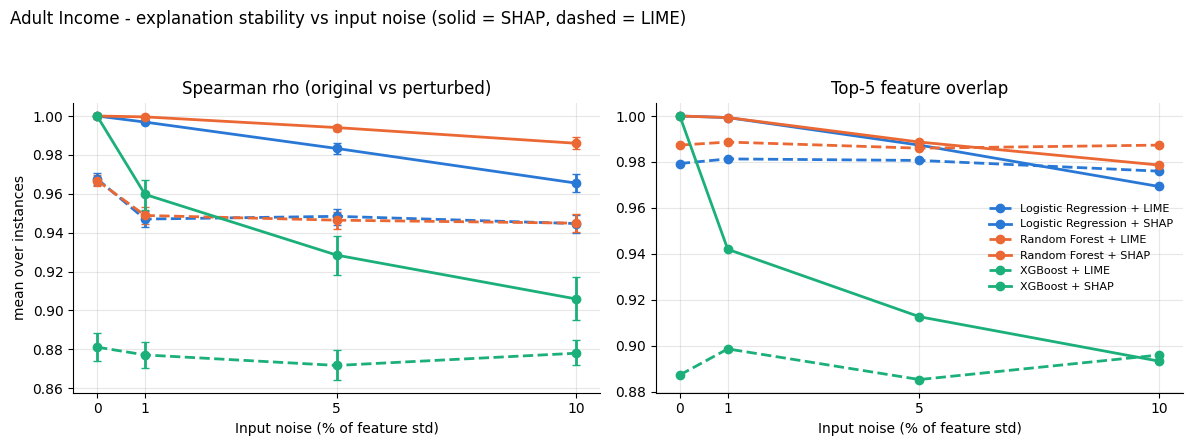

=== compas: mean Spearman rho ===


noise                          0%     1%    10%     5%
model               method                            
logistic_regression lime    0.815  0.766  0.758  0.761
                    shap    1.000  0.998  0.972  0.992
random_forest       lime    0.858  0.748  0.740  0.748
                    shap    1.000  0.998  0.902  0.955
xgboost             lime    0.730  0.633  0.639  0.630
                    shap    1.000  0.927  0.895  0.922

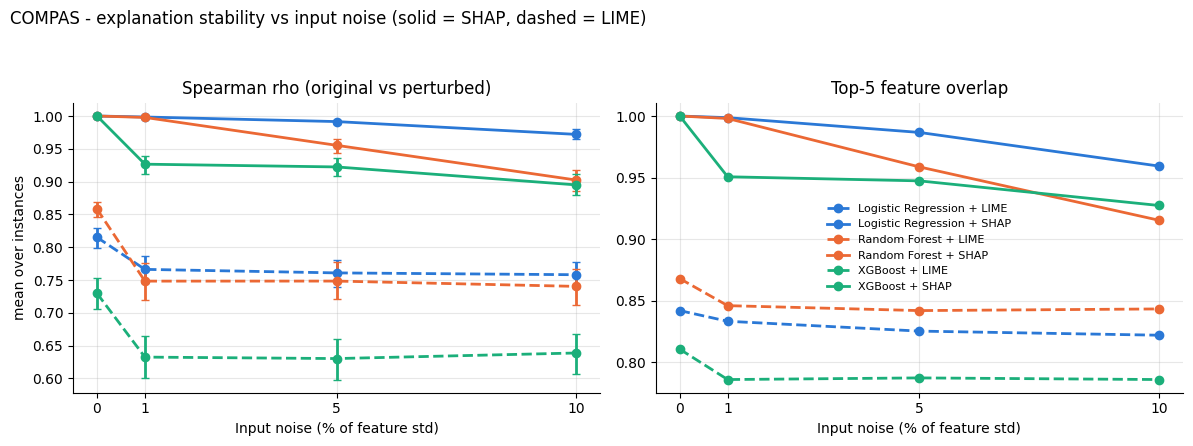

In [28]:
show_source(stability.make_perturbations)
stab = stability.run_stability_all(prepared, STABILITY_SETTINGS, N_BOOT)
summary = stab["stability_summary.csv"]
for name in config.DATASETS:
    part = summary[summary["dataset"] == name].copy()
    part["noise"] = (part["noise"] * 100).map(lambda v: f"{v:g}%")
    print(f"=== {name}: mean Spearman rho ===")
    display(part.pivot_table(index=["model", "method"], columns="noise", values="rho").round(3))
    display(stability.plot_stability_vs_noise(summary, name))

In [29]:
display(stab["stability_test_shap_vs_lime.csv"][["dataset", "model", "noise", "metric", "shap_mean", "lime_mean",
                                                    "p_holm", "reject_h0"]].round(4))
display(stab["stability_test_models.csv"][["dataset", "method", "noise", "metric", "kendalls_w", "p_holm",
                                           "reject_h0"]].round(3))
display(stab["stability_by_group.csv"][["dataset", "model", "method", "attribute", "rho_privileged",
                                        "rho_unprivileged", "p_holm", "reject_h0"]].round(3))

,dataset,model,noise,metric,shap_mean,lime_mean,p_holm,reject_h0
0,adult,logistic_regression,0.01,rho,0.9969,0.9470,0.0000,True
1,adult,logistic_regression,0.05,rho,0.9833,0.9484,0.0000,True
2,adult,logistic_regression,0.10,rho,0.9655,0.9447,0.0000,True
3,adult,random_forest,0.01,rho,0.9996,0.9489,0.0000,True
4,adult,random_forest,0.05,rho,0.9941,0.9464,0.0000,True
5,adult,random_forest,0.10,rho,0.9860,0.9449,0.0000,True
6,adult,xgboost,0.01,rho,0.9597,0.8771,0.0000,True
7,adult,xgboost,0.05,rho,0.9285,0.8717,0.0000,True
8,adult,xgboost,0.10,rho,0.9059,0.8780,0.0000,True
9,compas,logistic_regression,0.01,rho,0.9985,0.7663,0.0000,True


,dataset,method,noise,metric,kendalls_w,p_holm,reject_h0
0,adult,lime,0.01,rho,0.407,0.0,True
1,adult,lime,0.05,rho,0.415,0.0,True
2,adult,lime,0.10,rho,0.329,0.0,True
3,adult,shap,0.01,rho,0.406,0.0,True
4,adult,shap,0.05,rho,0.331,0.0,True
5,adult,shap,0.10,rho,0.335,0.0,True
6,compas,lime,0.01,rho,0.139,0.0,True
7,compas,lime,0.05,rho,0.175,0.0,True
8,compas,lime,0.10,rho,0.119,0.0,True
9,compas,shap,0.01,rho,0.421,0.0,True


,dataset,model,method,attribute,rho_privileged,rho_unprivileged,p_holm,reject_h0
0,adult,logistic_regression,lime,sex,0.946,0.948,1.000,False
1,adult,logistic_regression,shap,sex,0.982,0.983,1.000,False
2,adult,random_forest,lime,sex,0.947,0.947,1.000,False
3,adult,random_forest,shap,sex,0.993,0.994,1.000,False
4,adult,xgboost,lime,sex,0.874,0.879,1.000,False
5,adult,xgboost,shap,sex,0.934,0.926,1.000,False
6,adult,logistic_regression,lime,race,0.947,0.943,1.000,False
7,adult,logistic_regression,shap,race,0.981,0.985,1.000,False
8,adult,random_forest,lime,race,0.948,0.936,1.000,False
9,adult,random_forest,shap,race,0.993,0.993,1.000,False


## 12. Automated tests
**What:** runs the project's 61 pytest tests: datasets load without leakage columns, no missing values after
preprocessing, the one-hot mapping is correct, probabilities are in [0, 1], fairness metrics are in range, identical
rankings give rho = 1, Holm values match a hand calculation, mitigation reduces the gap, and more.

**Look for:** `61 passed`.

In [30]:
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no"], cwd=PROJECT_ROOT, capture_output=True, text=True)
print(result.stdout[-1500:] or result.stderr[-1500:])

.............................................................            [100%]
61 passed in 16.48s



## 13. Summary of findings (computed from this run)
**What:** the key numbers, read from the tables produced above - nothing is typed in by hand.

In [31]:
print("RQ1 - fairness")
print(f"  {int((fair['dp_ratio'] < 0.8).sum())} of {len(fair)} combinations fail the four-fifths rule "
      f"(DP ratio {fair['dp_ratio'].min():.2f} to {fair['dp_ratio'].max():.2f}).")
compas_race = fair[(fair.dataset == "compas") & (fair.attribute == "race") & (fair.setting == "with_sensitive")]
print(f"  COMPAS race: gap in the data {compas_race['base_rate_difference'].iloc[0]:.2f}, model gaps "
      f"{compas_race['dp_difference'].min():.2f}-{compas_race['dp_difference'].max():.2f}.")

print("RQ2/RQ3 - explanations across groups")
sig = tests[tests["significant_holm"]]
print(f"  {len(sig)} of {len(tests)} tests significant after Holm "
      f"({', '.join(f'{m}: {n}' for m, n in sig['method'].value_counts().items()) or 'none'}).")
print(f"  Median Spearman rho between groups: {comparison['spearman_rho'].median():.2f} "
      f"(lowest {comparison['spearman_rho'].min():.2f}).")

print("RQ4 - trade-off")
print(f"  {int(tradeoff['is_pareto'].sum())} of {len(tradeoff)} rows Pareto-optimal.")

print("Mitigation")
for row in mitigated[(mitigated.attribute == mitigated.constrained_attribute)
                     & (mitigated.setting == "with_sensitive")].to_dict("records"):
    print(f"  {row['dataset']} {row['stage']:6s}: DP {row['dp_difference']:.3f}, EO {row['eo_difference']:.3f}, "
          f"accuracy {row['accuracy']:.3f}")

print("Stability")
t1 = stab["stability_test_shap_vs_lime.csv"]
rejected = t1[t1["reject_h0"]]
print(f"  SHAP vs LIME: H0 rejected in {len(rejected)} of {len(t1)} tests; SHAP more stable in "
      f"{int((rejected['shap_mean'] > rejected['lime_mean']).sum())} of them.")
base = summary[summary["noise"] == 0]
print(f"  0% noise baseline rho - SHAP: {base[base.method == 'shap']['rho'].min():.2f}-"
      f"{base[base.method == 'shap']['rho'].max():.2f}, LIME: {base[base.method == 'lime']['rho'].min():.2f}-"
      f"{base[base.method == 'lime']['rho'].max():.2f}")

RQ1 - fairness
  24 of 24 combinations fail the four-fifths rule (DP ratio 0.27 to 0.67).
  COMPAS race: gap in the data 0.13, model gaps 0.23-0.28.
RQ2/RQ3 - explanations across groups
  17 of 96 tests significant after Holm (shap: 17).
  Median Spearman rho between groups: 0.98 (lowest 0.71).
RQ4 - trade-off
  37 of 48 rows Pareto-optimal.
Mitigation
  adult before: DP 0.180, EO 0.124, accuracy 0.843
  adult after : DP 0.003, EO 0.334, accuracy 0.829
  compas before: DP 0.272, EO 0.328, accuracy 0.669
  compas after : DP 0.023, EO 0.058, accuracy 0.647
Stability
  SHAP vs LIME: H0 rejected in 30 of 36 tests; SHAP more stable in 30 of them.
  0% noise baseline rho - SHAP: 1.00-1.00, LIME: 0.73-0.97


### Key points for the viva
1. **SHAP group gaps partly reflect group size** - SHAP compares people with a majority-dominated average.
2. **COMPAS models amplify the racial gap** that already exists in the data.
3. **Fairness through unawareness is not enough** - reliance moves to proxies such as relationship and marital status.
4. **Demographic-parity mitigation can worsen equal opportunity** when base rates differ.
5. **LIME varies even without any input change**; Tree/Linear SHAP is deterministic.

### Limitations
Two datasets and binary groups only; explanations on samples (wider CIs for small groups); LIME fidelity measured on
LIME's synthetic neighbourhood; proxies by mutual information show association, not causation. COMPAS is
criminal-justice data about real people - the project audits bias and does not endorse such models.

## 14. Save the results
**What:** zips `results/` and `models/`. In Colab the zip is downloaded to your computer (and copied to Drive if
`USE_DRIVE = True` was used, since the project then already lives there).

**Why:** Colab's `/content` folder is deleted when the session ends. To use these results in the dashboard, unzip them
into the project folder on your laptop and run `python -m streamlit run app/Home.py`.

In [32]:
import shutil

archive = shutil.make_archive(str(PROJECT_ROOT / "fairness_xai_results"), "zip", root_dir=PROJECT_ROOT,
                              base_dir="results")
models_zip = shutil.make_archive(str(PROJECT_ROOT / "fairness_xai_models"), "zip", root_dir=PROJECT_ROOT,
                                 base_dir="models")
print("Created:", archive, "and", models_zip)
if IN_COLAB and not USE_DRIVE:
    from google.colab import files
    files.download(archive)
    files.download(models_zip)

Created: C:\Users\tarun\Desktop\Mini Project\fairness-xai\fairness_xai_results.zip and C:\Users\tarun\Desktop\Mini Project\fairness-xai\fairness_xai_models.zip
